In [142]:
import numpy as np
import pandas as pd
import gzip
import json
import os
import random
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
#Visualization
import matplotlib.pyplot as plt
import seaborn as sns


from pyspark.sql import SparkSession
from collections import Counter
from pyspark.sql.functions import length, substring
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [88]:
spark = SparkSession.builder \
    .appName("BookAuthourClassification")\
    .config("spark.driver.memory", "4g")\
    .config("spark.sql.shuffle.partitions", "8")\
    .getOrCreate()


In [46]:
file_path = r"C:\Users\maduo\.cache\huggingface\hub\datasets--next-token--clean-PD-16000-books3\snapshots\026eb35a777041482854033ccbd85da25afad542\pd_books2.json.gz"


In [47]:
os.path.exists(file_path)

True

In [48]:
books_df = spark.read.json(file_path)
books_df.printSchema()

root
 |-- author: string (nullable = true)
 |-- language: string (nullable = true)
 |-- subjects: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- text: string (nullable = true)
 |-- title: string (nullable = true)



In [49]:
books_df.count()

15817

In [50]:
books_df.select("title", "author", "language").show(5, truncate= False)

+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---------------------------------------------------------+--------+
|title                                                                                                                                                                                                                                                                                 |author                                                   |language|
+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+------------------------

In [51]:
author_counts = books_df.groupBy("author").count()
author_counts.orderBy("count", ascending = False).show(20, truncate= False)

+----------------------------------------------------------------------------------------------------------------------+-----+
|author                                                                                                                |count|
+----------------------------------------------------------------------------------------------------------------------+-----+
|Various                                                                                                               |1024 |
|Anonymous                                                                                                             |170  |
|Twain, Mark, 1835-1910                                                                                                |115  |
|Ballantyne, R. M. (Robert Michael), 1825-1894                                                                         |81   |
|Howells, William Dean, 1837-1920                                                                              

By viewing the first 20 count of authors shows authors with the most books to the least. This is also to see if there are any missing value, duplicates, or inconsistencies. 

In [52]:
clean_books = books_df.filter(~books_df.author.isin("Various", "Anonymous", "Unknown"))
clean_books.count()

14557

The dataset has been cleaned for books with anonymous authors, then counted the remaining books.

In [53]:
clean_books.filter(clean_books.author.isNull()).count()

0

The dataset is being checked for any missing values and being counted, and this dataset has no missing values.

In [54]:
author_counts = clean_books.groupBy("author").count()
author_counts.orderBy("count", ascending = False).show(30, truncate= False)

+----------------------------------------------------------------------------------------------------------------------+-----+
|author                                                                                                                |count|
+----------------------------------------------------------------------------------------------------------------------+-----+
|Twain, Mark, 1835-1910                                                                                                |115  |
|Ballantyne, R. M. (Robert Michael), 1825-1894                                                                         |81   |
|Howells, William Dean, 1837-1920                                                                                      |72   |
|Various, Seaman, Owen, Sir, 1861-1936 [Editor]                                                                        |72   |
|Kingston, William Henry Giles, 1814-1880                                                                      

This is showing the first 30 authors in descending order according to how many books each author has after cleaning the dataset.

In [55]:
authors_20plus = author_counts.filter(author_counts["count"] >= 20)
authors_20plus.orderBy("count", ascending = False).show(50, truncate= False)

+----------------------------------------------------------------------------------------------------------------------+-----+
|author                                                                                                                |count|
+----------------------------------------------------------------------------------------------------------------------+-----+
|Twain, Mark, 1835-1910                                                                                                |115  |
|Ballantyne, R. M. (Robert Michael), 1825-1894                                                                         |81   |
|Howells, William Dean, 1837-1920                                                                                      |72   |
|Various, Seaman, Owen, Sir, 1861-1936 [Editor]                                                                        |72   |
|Kingston, William Henry Giles, 1814-1880                                                                      

This shows the 50 first authors with atleast 20 books each.

In [56]:
selected_authors = [
    "Twain, Mark, 1835-1910",
    "Ballantyne, R. M. (Robert Michael), 1825-1894",
    "Howells, William Dean, 1837-1920",
    "Kingston, William Henry Giles, 1814-1880",
    "Haggard, Henry Rider, 1856-1925"
]

This creates a list of the five author labels we want to study.

In [57]:
selected_books = clean_books.filter(clean_books.author.isin(selected_authors))
selected_books.groupBy("author")\
    .count()\
    .orderBy("count", ascending = False)\
    .show(truncate=False)

+---------------------------------------------+-----+
|author                                       |count|
+---------------------------------------------+-----+
|Twain, Mark, 1835-1910                       |115  |
|Ballantyne, R. M. (Robert Michael), 1825-1894|81   |
|Howells, William Dean, 1837-1920             |72   |
|Kingston, William Henry Giles, 1814-1880     |67   |
|Haggard, Henry Rider, 1856-1925              |49   |
+---------------------------------------------+-----+



A count was done for the five book classes and to also ensure that spark has found the expected books for each of the five classes.

Train-Test Book splitting:
This split will have 70% for training, 15% for Validation and 15% for testing.

In [58]:
train_books, temp_books = selected_books.randomSplit([0.70, 0.30], seed=42)

From the books of our selected authors, there is a random split of 70% into one dataframe and 30% into the other. 

In [59]:
validation_books, test_books = temp_books.randomSplit([0.50,0.50], seed = 42)

Since temp contains 30% of the books, then we separate it into 15% validation and 15% test.

In [60]:
print("Training books:", train_books.count())
print("Validation books:", validation_books.count())
print("Test books:", test_books.count())

Training books: 289
Validation books: 41
Test books: 54


In [61]:
train_summary = train_books.groupBy("author").count()\
    .withColumnRenamed("count","train")
validation_summary = validation_books.groupBy("author").count()\
    .withColumnRenamed("count", "validation")
test_summary = test_books.groupBy("author").count()\
    .withColumnRenamed("count","test")

In [62]:
split_summary = train_summary\
    .join(validation_summary, "author", "outer")\
    .join(test_summary, "author", "outer")
split_summary.orderBy("author").show(truncate = False)

+---------------------------------------------+-----+----------+----+
|author                                       |train|validation|test|
+---------------------------------------------+-----+----------+----+
|Ballantyne, R. M. (Robert Michael), 1825-1894|48   |11        |22  |
|Haggard, Henry Rider, 1856-1925              |39   |5         |5   |
|Howells, William Dean, 1837-1920             |60   |4         |8   |
|Kingston, William Henry Giles, 1814-1880     |51   |7         |9   |
|Twain, Mark, 1835-1910                       |91   |14        |10  |
+---------------------------------------------+-----+----------+----+



This checks how the books are split at each stage and to insure that each author has a book split at each stage of the processing,so that there's no split with zero books.

In [63]:
lstm_train = train_books.select("text", "author")
lstm_validation = validation_books.select("text", "author")
lstm_test = test_books.select("text", "author")

In [69]:
selected_books.select(
    "author",
    length("text").alias("text_length")
).show(20, truncate=False)

+---------------------------------------------+-----------+
|author                                       |text_length|
+---------------------------------------------+-----------+
|Ballantyne, R. M. (Robert Michael), 1825-1894|498911     |
|Ballantyne, R. M. (Robert Michael), 1825-1894|529712     |
|Twain, Mark, 1835-1910                       |171016     |
|Ballantyne, R. M. (Robert Michael), 1825-1894|534984     |
|Twain, Mark, 1835-1910                       |73177      |
|Howells, William Dean, 1837-1920             |419689     |
|Howells, William Dean, 1837-1920             |274721     |
|Kingston, William Henry Giles, 1814-1880     |181787     |
|Twain, Mark, 1835-1910                       |88387      |
|Kingston, William Henry Giles, 1814-1880     |951360     |
|Haggard, Henry Rider, 1856-1925              |595630     |
|Ballantyne, R. M. (Robert Michael), 1825-1894|249923     |
|Twain, Mark, 1835-1910                       |353230     |
|Howells, William Dean, 1837-1920       

This calculated how much text/ characters are contained in the top 20 books, they go from approximately 20 000 to 1 million, this helps us in deciding  how to prepare the LSTM data, from here the books will be sectioned into sequences, which are small bits that will be fed into the LSTM model.

In [71]:
sample_book = selected_books.select("text", "author").limit(1).collect()[0]
print(sample_book["author"])
print(len(sample_book["text"]))

Ballantyne, R. M. (Robert Michael), 1825-1894
498911


In [78]:
sequence_lenth = 100

def create_sequences(text, sequence_length=100):
    sequences = []

    for i in range(0, len(text) - sequence_length + 1, sequence_length):
        sequence = text[i:i + sequence_length]
        sequences.append(sequence)

    return sequences



The sequences will be sectioned into sections of 100s, this is because 100 is short enough to keep computation manageable, and long enough to capture punctuations, spacing, capitalization and reccuring character patterns

In [82]:
train_records = train_books.select("text", "author").collect()
len(train_records)

289

In [84]:
X_train_text = []
y_train_author = []

for record in train_records:
    sequences = create_sequences(record["text"])

    for sequence in sequences:
        X_train_text.append(sequence)
        y_train_author.append(record["author"])

len(X_train_text)


889088

This creates a sequence for all the books in the training dataset and there are a total of 889088

In [86]:
sequence_counts = Counter(y_train_author)
sequence_counts

Counter({'Haggard, Henry Rider, 1856-1925': 194223,
         'Kingston, William Henry Giles, 1814-1880': 192372,
         'Howells, William Dean, 1837-1920': 183296,
         'Ballantyne, R. M. (Robert Michael), 1825-1894': 182702,
         'Twain, Mark, 1835-1910': 136495})

This counts the number of sequences per author, it is important to check the balance of the sequences, since the number of books is not equal to the amount of training data.

In [89]:
min_sequences = min(sequence_counts.values())
min_sequences

136495

This takes out the book with the smallest sequence count in all sequences in the selected books and the smallest has 136 495.

In [92]:
sequences_per_author = 20000
balanced_train_sequence = []

for author in selected_authors:
    author_sequnces = [
        sequence
        for sequence, label in zip(X_train_text, y_train_author)
        if label == author
    ]

    random.seed(42)
    sampled_sequences = random.sample(author_sequnces, sequences_per_author)

    balanced_train_sequence.extend(
        [(sequence, author) for sequence in sampled_sequences]
    )

We have decided to have 20 000 sequences from each training book, this is because 136495 is a large sequence to train which might consume a lot of memory and time.

In [94]:
Counter(author for sequence, author in balanced_train_sequence)

Counter({'Twain, Mark, 1835-1910': 20000,
         'Ballantyne, R. M. (Robert Michael), 1825-1894': 20000,
         'Howells, William Dean, 1837-1920': 20000,
         'Kingston, William Henry Giles, 1814-1880': 20000,
         'Haggard, Henry Rider, 1856-1925': 20000})

In [ ]:
validation_records = validation_books.select("text", "author").collect()

X_validation_text = []
y_validation_author = []

for record in validation_records:
    sequences = create_sequences(record["text"])

    for sequence in sequences:
        X_validation_text.append(sequence)
        y_validation_author.append(record["author"])

len(X_validation_text)
len(y_validation_author)


110994

This creates sequences for the validation dataset, and the count of the sequences which is 110994.

In [100]:
X_validation_text = []
y_validation_author = []

for record in validation_books.select("text", "author").toLocalIterator():
    sequences = create_sequences(record["text"])

    for sequence in sequences:
        X_validation_text.append(sequence)
        y_validation_author.append(record["author"])

print("Validation sequences:", len(X_validation_text))
print("Validation labels:", len(y_validation_author))

Validation sequences: 110994
Validation labels: 110994


In [101]:
test_records = test_books.select("text", "author").collect()

X_test_text = []
y_test_author = []

for record in test_records:
    sequences = create_sequences(record["text"])

    for sequence in sequences:
        X_test_text.append(sequence)
        y_test_author.append(record["author"])

len(X_test_text)
len(y_test_author)

164512

In [103]:
vocab = sorted(set("".join(X_train_text)))

char_to_int = {char: i+1 for i, char in enumerate(vocab)}
print("Number of characters:", len(char_to_int))
print(list(char_to_int.items())[:20])

Number of characters: 253
[('\n', 1), (' ', 2), ('!', 3), ('"', 4), ('#', 5), ('$', 6), ('&', 7), ("'", 8), ('(', 9), (')', 10), ('*', 11), ('+', 12), (',', 13), ('-', 14), ('.', 15), ('/', 16), ('0', 17), ('1', 18), ('2', 19), ('3', 20)]


In [106]:
X_train_text = [item[0] for item in balanced_train_sequence]
y_train_author = [item[1] for item in balanced_train_sequence]

print("Training sequences:", len(X_train_text))
print("Training labels:", len(y_train_author))

Training sequences: 100000
Training labels: 100000


In [118]:
author_to_int = {
    author: i
    for i, author in enumerate(selected_authors)
}

In [119]:
X_train = [
    [char_to_int[char] for char in sequence]
    for sequence in X_train_text
]
y_train = [
    author_to_int[author]
    for author in y_train_author
]
print(X_train[0])
print(len(X_train[0]))
print("Training sequences:", len(X_train))

print(y_train)

[2, 68, 77, 83, 80, 2, 70, 83, 76, 66, 80, 67, 66, 2, 87, 67, 63, 80, 81, 13, 2, 40, 2, 68, 67, 67, 74, 2, 63, 2, 66, 67, 81, 71, 80, 67, 2, 82, 77, 2, 64, 67, 74, 71, 67, 84, 67, 2, 82, 70, 67, 2, 74, 67, 69, 67, 76, 66, 2, 68, 77, 80, 2, 40, 51, 50, 2, 81, 63, 73, 67, 28, 2, 81, 77, 2, 40, 2, 85, 71, 74, 74, 2, 70, 83, 75, 77, 80, 2, 82, 70, 67, 2, 66, 67, 81, 71, 80, 67, 13]
100
Training sequences: 100000
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

Convert the validation sequences

In [120]:
X_validation = [
    [char_to_int.get(char, 0) for char in sequence]
    for sequence in X_validation_text
]
print("Validation sequences:", len(X_validation))
print("Characters per sequence:", len(X_validation[0]))

Validation sequences: 110994
Characters per sequence: 100


In [167]:
y_validation = [
    author_to_int[author]
    for author in y_validation_author
]
for author, number in author_to_int.items():
    print(author, ":", number)
print()
print(y_validation[:10])



Twain, Mark, 1835-1910 : 0
Ballantyne, R. M. (Robert Michael), 1825-1894 : 1
Howells, William Dean, 1837-1920 : 2
Kingston, William Henry Giles, 1814-1880 : 3
Haggard, Henry Rider, 1856-1925 : 4

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


Names of authors are converted into numbers to make it easier for the LSTM's output layer. This creates a list for the selected authors.

This turns the correct validation author names into numbers so we can compare them with the LSTM's numerical predictions.

In [122]:
X_test = [
    [char_to_int.get(char, 0) for char in sequence]
    for sequence in X_test_text
]
y_test = [
    author_to_int[author]
    for author in y_test_author
]

print("Test sequences:", len(X_test))
print("Characters per sequence:", len(X_test[0]))
print(y_test[:10])

Test sequences: 164512
Characters per sequence: 100
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [124]:
X_train = np.array(X_train)
X_validation = np.array(X_validation)
X_test = np.array(X_test)

y_train = np.array(y_train)
y_validation = np.array(y_validation)
y_test = np.array(y_test)

print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_validation:", y_validation.shape)
print("y_test:", y_test.shape)

X_train: (100000, 100)
X_validation: (110994, 100)
X_test: (164512, 100)
y_train: (100000,)
y_validation: (110994,)
y_test: (164512,)


The data is converted into NumPy arrays

In [128]:
model = Sequential()

model.add(Embedding(
    input_dim= len(char_to_int) +1,
    output_dim= 32,
    input_shape = (100,)
))
model.add(LSTM(64))
model.add(Dropout(0.3))
model.add(Dense(5, activation= "softmax"))
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 32)        │         8,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,285 (130.02 KB)

 Trainable params: 33,285 (130.02 KB)

 Non-trainable params: 0 (0.00 B)

Since there are 253 character, by embedding the model gets a way of representing each character using numbers we can learn from, 32 means each character gets represented using 32 learned values, the LSTM(64) looks at the sequence of 100 characters and learns habits including punctuations, character combinations, spelling patterns, writing style and the dropout helps the model forget about 30% of some connections so that the model just does not memorise the training data.

In [129]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [131]:
early_stopping = EarlyStopping(
    monitor = "val_loss",
    patience = 3,
    restore_best_weights = True
)

In [132]:
history = model.fit(
    X_train,
    y_train,
    validation_data = (X_validation, y_validation),
    epochs = 20,
    batch_size = 128,
    callbacks = [early_stopping]
)

Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 103s 127ms/step - accuracy: 0.2544 - loss: 1.5821 - val_accuracy: 0.2929 - val_loss: 1.5304
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 98s 125ms/step - accuracy: 0.2988 - loss: 1.5481 - val_accuracy: 0.2771 - val_loss: 1.5104
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 101s 129ms/step - accuracy: 0.3153 - loss: 1.5324 - val_accuracy: 0.3423 - val_loss: 1.4842
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 98s 126ms/step - accuracy: 0.3291 - loss: 1.5172 - val_accuracy: 0.3195 - val_loss: 1.4846
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 98s 125ms/step - accuracy: 0.3344 - loss: 1.5065 - val_accuracy: 0.3164 - val_loss: 1.4804
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 97s 125ms/step - accuracy: 0.3462 - loss: 1.4933 - val_accuracy: 0.3214 - val_loss: 1.4817
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 98s 125ms/step - accuracy: 0.3563 - loss: 1.4761 - val_accuracy: 0.3645 - val_loss: 1.4388
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 98s 125ms/step - accuracy: 0.3679 - loss:

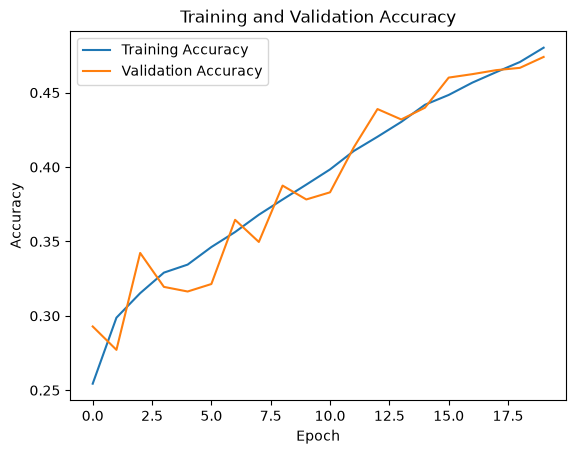

In [133]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

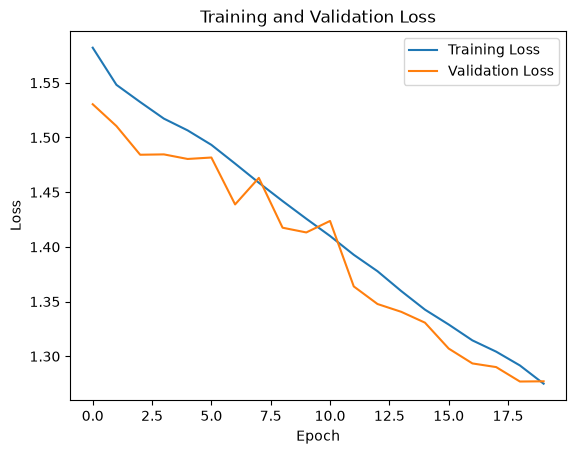

In [134]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [135]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test
)

5141/5141 ━━━━━━━━━━━━━━━━━━━━ 83s 16ms/step - accuracy: 0.4219 - loss: 1.3256


In [ ]:
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 1.3256314992904663
Test Accuracy: 0.42193275690078735


In [138]:
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis = 1)
print(y_test[:10])

5141/5141 ━━━━━━━━━━━━━━━━━━━━ 77s 15ms/step
[1 1 1 1 1 1 1 1 1 1]


In [141]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 3781  1311  1452  1998   989]
 [ 8661 29605  6754 26042  8254]
 [ 1557  1514  4211  2845  1316]
 [ 3464  6093  2801 21850  4057]
 [ 2575  4433  2724  6259  9966]]


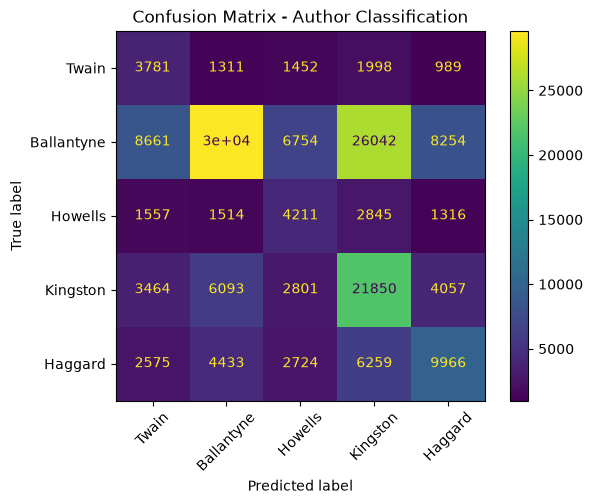

In [143]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Twain", "Ballantyne", "Howells", "Kingston", "Haggard"]
)

disp.plot()

plt.title("Confusion Matrix - Author Classification")
plt.xticks(rotation=45)
plt.show()

According to this Confusion matrix, the most correctly identified sequences are Ballantyne with 30 000 correct prediction. Kingston is also doing well with 21850 correct predictions. The model has a big struggle between Ballantyne and Kingston with Ballantyne mistaken for Kingston with 26042 predictions, And Kingston mistaken for Ballantyne with 6093 predictions. 

In [144]:
report = classification_report(
    y_test, 
    y_pred, 
    target_names= [
        "Twain",
        "Ballantyne",
        "Howells",
        "Kingston",
        "Haggard"
    ]
)
print(report)

              precision    recall  f1-score   support

       Twain       0.19      0.40      0.26      9531
  Ballantyne       0.69      0.37      0.48     79316
     Howells       0.23      0.37      0.29     11443
    Kingston       0.37      0.57      0.45     38265
     Haggard       0.41      0.38      0.39     25957

    accuracy                           0.42    164512
   macro avg       0.38      0.42      0.37    164512
weighted avg       0.51      0.42      0.43    164512



From the classification report, with a precision of 19% means the model is most likely wrong when it predicts "Twain", it can predict Twain well with 40% and with F1 of 26%, model has a hard time classifying Twain.

Ballantyne, has the highest precision with 69% meaning the model is usual correct when predicting Ballantyne. But only correctly catch 37% of the Ballantyne sequences. Has F1 of 48% , meaning the model does well with classifying Ballantyne.

Howells has a precision of 23%, which is the approximate average with 5 authors, it has a fairly good chance of catching Howells, and an F1 of 29%. Overall the model also has a hard time distinguishing Howells.

Kignston has the highest recall with 57% meaning the model is good at catching Kingston sequences, with F1 of 45% meaning the model does relatively good with classifying Kingstone, with precision of 37%.

Haggard, has 41% precision , Recall of 38% and F1 of 39% which sits in the middle of the five.

In [155]:
authors = [
    "Twain",
    "Ballantyne",
    "Howells",
    "Kingston",
    "Haggard"
]

for i, author in enumerate(authors):
    correct = cm[i,i]
    total = cm[i].sum()
    accuracy = correct/total

    print(author, ":", round(accuracy * 100, 2), "%")



Twain : 39.67 %
Ballantyne : 37.33 %
Howells : 36.8 %
Kingston : 57.1 %
Haggard : 38.39 %


Calculating the correct classification for each author for all the books thy have. Kingston is the highest with 57.1%, meaning out of all the books he has, that is how many were correctly identified and we have the lowest with Howells at 36.8%

The overall evaluation:
The overall test accuracy achieved by the model is 42.19%, which is above the 20% random baseline. The best identified author is Kingston with 57.1% and the challenging author to identify is Howells with 36.8% and the model frequently confuses Ballantyne for  Kingston. The model has a macro accuracy 0f 37% meaning, when each class is treated with equal importance.

IMPROVED LSTM Model

In [158]:
improved_model = Sequential()
improved_model.add(Embedding(
    input_dim=len(char_to_int) + 1,
    output_dim=32,
    input_shape=(100,)
))

improved_model.add(LSTM(128))
improved_model.add(Dropout(0.3))
improved_model.add(Dense(5, activation= "softmax"))
improved_model.summary()

C:\Users\maduo\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\embedding.py:126: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 100, 32)        │         8,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 128)            │        82,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,205 (356.27 KB)

 Trainable params: 91,205 (356.27 KB)

 Non-trainable params: 0 (0.00 B)

In [159]:
improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [160]:
improved_history = improved_model.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping]
)

Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 240s 302ms/step - accuracy: 0.2356 - loss: 1.5943 - val_accuracy: 0.2788 - val_loss: 1.5562
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 237s 303ms/step - accuracy: 0.2807 - loss: 1.5633 - val_accuracy: 0.2861 - val_loss: 1.5245
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 238s 304ms/step - accuracy: 0.3093 - loss: 1.5399 - val_accuracy: 0.3148 - val_loss: 1.4999
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 235s 301ms/step - accuracy: 0.3199 - loss: 1.5254 - val_accuracy: 0.2481 - val_loss: 1.5712
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 327s 418ms/step - accuracy: 0.3294 - loss: 1.5094 - val_accuracy: 0.3460 - val_loss: 1.4785
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 208s 266ms/step - accuracy: 0.3462 - loss: 1.4901 - val_accuracy: 0.3101 - val_loss: 1.4900
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 203s 259ms/step - accuracy: 0.3624 - loss: 1.4658 - val_accuracy: 0.3981 - val_loss: 1.4069
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 197s 252ms/step - accuracy: 0.3805 -

In [161]:
improved_test_loss, improved_test_accuracy = improved_model.evaluate(
    X_test,
    y_test
)

print("Improved Test Accuracy:", improved_test_accuracy)

5141/5141 ━━━━━━━━━━━━━━━━━━━━ 160s 31ms/step - accuracy: 0.4480 - loss: 1.3108
Improved Test Accuracy: 0.4480098783969879


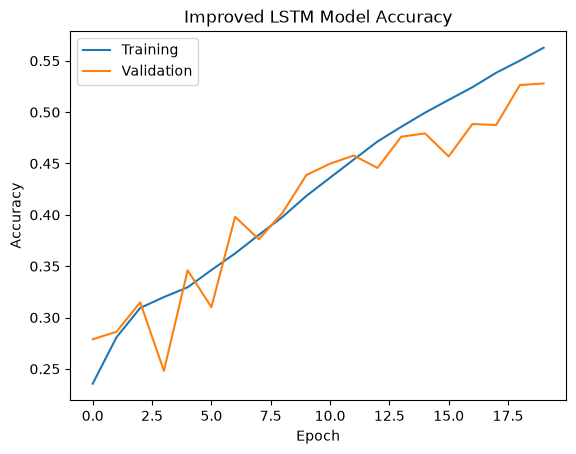

In [162]:
import matplotlib.pyplot as plt

plt.plot(improved_history.history["accuracy"])
plt.plot(improved_history.history["val_accuracy"])

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Training", "Validation"])
plt.title("Improved LSTM Model Accuracy")

plt.show()

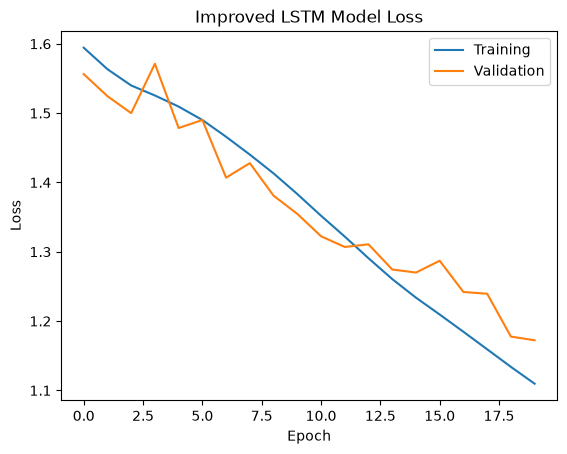

In [163]:
plt.plot(improved_history.history["loss"])
plt.plot(improved_history.history["val_loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Training", "Validation"])
plt.title("Improved LSTM Model Loss")

plt.show()

In [164]:
print("Baseline Test Accuracy:", 42.19)
print("Improved Test Accuracy:", round(improved_test_accuracy * 100, 2))

improvement = (improved_test_accuracy * 100) - 42.19

print("Improvement:", round(improvement, 2), "percentage points")

Baseline Test Accuracy: 42.19
Improved Test Accuracy: 44.8
Improvement: 2.61 percentage points


To improve the model, the LSTM units was increased from 64 to 128, this icreases the capacity of the model to learn character level patterns in the author's writing styles. The accuracy of the baseline LSTM model and the improved LSTM model were compared using the accuracy vs Epoch and Loss vs Epoch graphs for the validation and training.

The improved LSTM model had an increase in the training and validation accuracy with the 20 epoches. The training accuracy increased to ~56% and the validation to ~53%, Although the validation accuracy fluctuated during the training, the training followed an upward trend indicating that the model learnt effectively without substantial overfitting. The baseline training accuracy was at ~48% and the validation accuracy at ~47%. The improved model had a test accuracy of 44.80% compared to the baseline model with 42.19% which was an improvement of 2.61%.

The loss curves on the LSTM improved method indicates a decrease on the training and validation loss with the 20 epochs. Training loss went from 1.59 to 1.11 and validation from 1.55 to 1.17, although with flactuations on the epochs, the was an overall decline, and there was not any sustained increase. The model learnt patterns without substantial overfitting.